# Understanding Data

In [ ]:
# Import pandas for loading, cleaning, and working with tabular data
import pandas as pd

In [ ]:
# Load the shared cleaned Adult Income baseline dataset
data = pd.read_csv("https://raw.githubusercontent.com/Derrick-Cummings/income-classification-benefits-screening/main/data/adult_baseline_clean.csv")

In [ ]:
# Display the original number of rows and columns before individual model preparation
data.shape

(48813, 17)

In [ ]:
# Display the first number of specified rows of the original baseline dataset
data.head(10)

,record_id,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_binary
0,1,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,1
1,2,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,1
2,3,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,1
3,4,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,1
4,5,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,1
5,6,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K,1
6,7,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K,1
7,8,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K,0
8,9,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K,0
9,10,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K,0


In [ ]:
# Display the last specified number of rows of the original baseline dataset
data.tail(10)

,record_id,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_binary
48803,48804,61,Private,89686,HS-grad,9,Married-civ-spouse,Sales,Husband,White,Male,0,0,48,United-States,<=50K,1
48804,48805,31,Private,440129,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K,1
48805,48806,25,Private,350977,HS-grad,9,Never-married,Other-service,Own-child,White,Female,0,0,40,United-States,<=50K,1
48806,48807,48,Local-gov,349230,Masters,14,Divorced,Other-service,Not-in-family,White,Male,0,0,40,United-States,<=50K,1
48807,48808,33,Private,245211,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Male,0,0,40,United-States,<=50K,1
48808,48809,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K,1
48809,48810,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States,<=50K,1
48810,48811,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K,1
48811,48812,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K,1
48812,48813,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K,0


In [ ]:
# Display the data type assigned to each column in the original baseline dataset
data.dtypes

,0
record_id,int64
age,int64
workclass,object
fnlwgt,int64
education,object
education_num,int64
marital_status,object
occupation,object
relationship,object
race,object


# Data Cleaning - Individual Model

#### Missinig Values

In [ ]:
# Check whether any missing values remain in the original baseline dataset
data.isnull().any().any()

np.True_

In [ ]:
# Display the number of missing values in each column of the original baseline dataset
data.isnull().sum()

,0
record_id,0
age,0
workclass,2799
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,2809
relationship,0
race,0


In [ ]:
# Count the number of missing values in each column of the original baseline dataset
per_column_total_nulls = data.isnull().sum()

In [ ]:
# Calculate the total number of missing values across the entire dataset of the original baseline dataset
total_nulls = per_column_total_nulls.sum()

In [ ]:
# Calculate the total number of cells of the original baseline dataset
total_cells = 48813 * 17

In [ ]:
# Calculate and display the overall percentage of missing values in the original baseline dataset
overall_percent_misisng_rate = total_nulls / total_cells * 100
overall_percent_misisng_rate

np.float64(0.7789631739857149)

In [ ]:
# Calculate and display the percentage of missing values in each column of the original baseline dataset
per_column_missing_rate = data.isnull().sum() / len(data) * 100
per_column_missing_rate

,0
record_id,0.000000
age,0.000000
workclass,5.734128
fnlwgt,0.000000
education,0.000000
education_num,0.000000
marital_status,0.000000
occupation,5.754615
relationship,0.000000
race,0.000000


In [ ]:
# Replace missing categorical values with the most common value in each column of the original baseline dataset and comfirm mode imputation was successful
data["workclass"] = data["workclass"].fillna(data["workclass"].mode()[0])
data["occupation"] = data["occupation"].fillna(data["occupation"].mode()[0])
data["native_country"] = data["native_country"].fillna(data["native_country"].mode()[0])


data[["workclass", "occupation", "native_country"]].isnull().sum()

,0
workclass,0
occupation,0
native_country,0


#### Removing Columns

In [ ]:
# Remove all columns that will not be used as predictors for modeling from the original baseline dataset, setting the orginal data frame to a new dataframe with the update
data_new = data.drop(columns=['fnlwgt', 'education', 'race', 'sex', 'income', 'record_id'])

In [ ]:
# Display the number of rows and columns remaining after removing unused fields using the updated data frame
data_new.shape

(48813, 11)

In [ ]:
# Display the first 10 rows after removing unused fields using the updated data frame
data_new.head(10)

,age,workclass,education_num,marital_status,occupation,relationship,capital_gain,capital_loss,hours_per_week,native_country,income_binary
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,2174,0,40,United-States,1
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,0,0,13,United-States,1
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,0,0,40,United-States,1
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,0,0,40,United-States,1
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,0,0,40,Cuba,1
5,37,Private,14,Married-civ-spouse,Exec-managerial,Wife,0,0,40,United-States,1
6,49,Private,5,Married-spouse-absent,Other-service,Not-in-family,0,0,16,Jamaica,1
7,52,Self-emp-not-inc,9,Married-civ-spouse,Exec-managerial,Husband,0,0,45,United-States,0
8,31,Private,14,Never-married,Prof-specialty,Not-in-family,14084,0,50,United-States,0
9,42,Private,13,Married-civ-spouse,Exec-managerial,Husband,5178,0,40,United-States,0


### Outliers

In [ ]:
# Import Matplotlib for creating data visualizations, including boxplots to prepare for outlier detection
import matplotlib.pyplot as plt

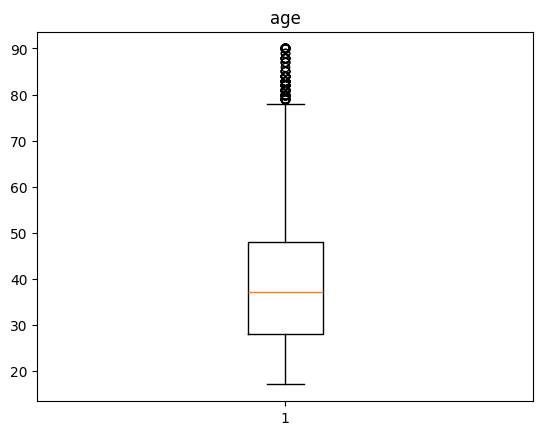

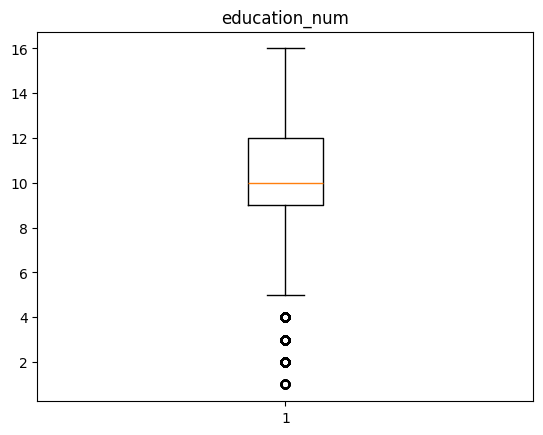

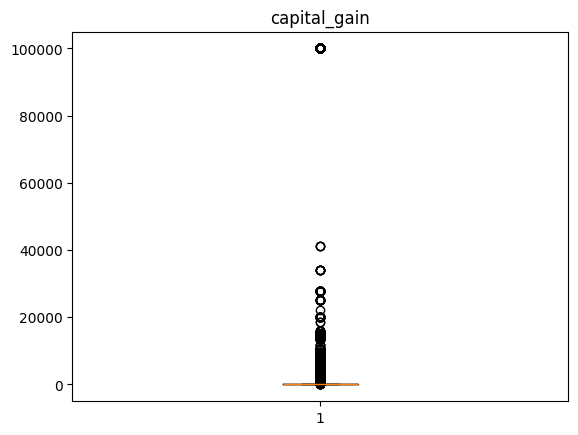

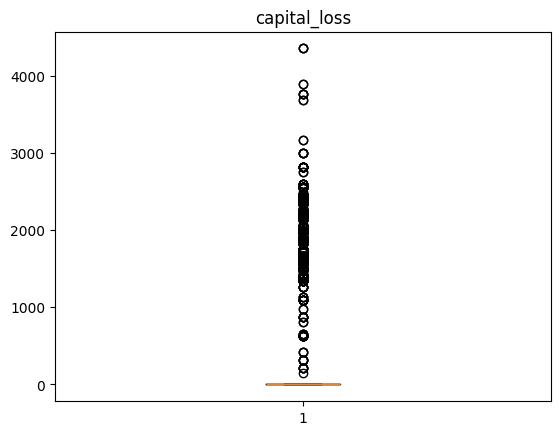

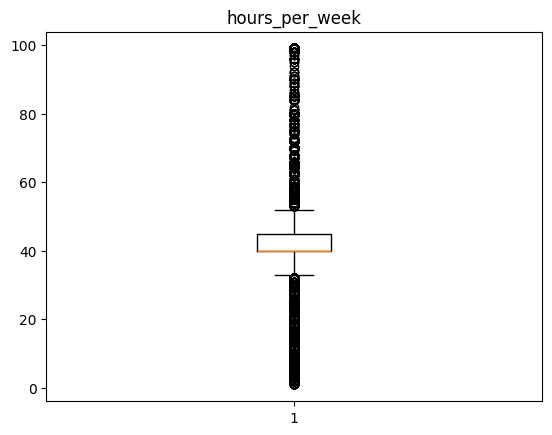

In [ ]:
# Create a separate boxplot for each numeric predictor to inspect its distribution and potential outliers
for col in ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]:
    plt.figure()
    plt.boxplot(data_new[col])
    plt.title(col)
    plt.show()

# Descriptive Statistics

### Summary Statistics - Numerical

In [ ]:
numeric_vars = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

data_new[numeric_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
age,48813.0,38.647348,13.709005,17.0,28.0,37.0,48.0,90.0
education_num,48813.0,10.078688,2.570257,1.0,9.0,10.0,12.0,16.0
capital_gain,48813.0,1079.708705,7454.185982,0.0,0.0,0.0,0.0,99999.0
capital_loss,48813.0,87.554299,403.118605,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48813.0,40.425051,12.390954,1.0,40.0,40.0,45.0,99.0


In [ ]:
summary_stats = data_new[numeric_vars].describe().T

summary_stats["median"] = data_new[numeric_vars].median()
summary_stats["IQR"] = (summary_stats["75%"] - summary_stats["25%"])

summary_stats

,count,mean,std,min,25%,50%,75%,max,median,IQR
age,48813.0,38.647348,13.709005,17.0,28.0,37.0,48.0,90.0,37.0,20.0
education_num,48813.0,10.078688,2.570257,1.0,9.0,10.0,12.0,16.0,10.0,3.0
capital_gain,48813.0,1079.708705,7454.185982,0.0,0.0,0.0,0.0,99999.0,0.0,0.0
capital_loss,48813.0,87.554299,403.118605,0.0,0.0,0.0,0.0,4356.0,0.0,0.0
hours_per_week,48813.0,40.425051,12.390954,1.0,40.0,40.0,45.0,99.0,40.0,5.0


In [ ]:
# Detirmnes the total counts for each category of the target variable
data_new["income_binary"].value_counts()

,count
income_binary,
1,37128
0,11685


In [ ]:
# Determines the porporition of each category as it contributes to the overall total of the target variable
data_new["income_binary"].value_counts(normalize=True) * 100

,proportion
income_binary,
1,76.061705
0,23.938295


### Summary Statistics - Categorical

In [ ]:
# Detirmnes the total counts for each category of the occupation (dependent) variable
data_new["occupation"].value_counts()

,count
occupation,
Prof-specialty,8976
Craft-repair,6107
Exec-managerial,6084
Adm-clerical,5608
Sales,5504
Other-service,4919
Machine-op-inspct,3019
Transport-moving,2355
Handlers-cleaners,2071


In [ ]:
# Determines the porporition of each category as it contributes to the overall total of the occupation (dependent) variable
data_new["occupation"].value_counts(normalize=True) * 100

,proportion
occupation,
Prof-specialty,18.388544
Craft-repair,12.511011
Exec-managerial,12.463893
Adm-clerical,11.488743
Sales,11.275685
Other-service,10.077234
Machine-op-inspct,6.184828
Transport-moving,4.824534
Handlers-cleaners,4.242722


In [ ]:
# Detirmnes the total counts for each category of the workclass (dependent) variable
data_new["workclass"].value_counts()

,count
workclass,
Private,36678
Self-emp-not-inc,3861
Local-gov,3136
State-gov,1981
Self-emp-inc,1694
Federal-gov,1432
Without-pay,21
Never-worked,10


In [ ]:
# Determines the porporition of each category as it contributes to the overall total of the workclass (dependent) variable
data_new["workclass"].value_counts(normalize=True) * 100

,proportion
workclass,
Private,75.139819
Self-emp-not-inc,7.909778
Local-gov,6.424518
State-gov,4.058345
Self-emp-inc,3.470387
Federal-gov,2.933645
Without-pay,0.043021
Never-worked,0.020486


In [ ]:
# Detirmnes the total counts for each category of the marital status (dependent) variable
data_new["marital_status"].value_counts()

,count
marital_status,
Married-civ-spouse,22372
Never-married,16098
Divorced,6630
Separated,1530
Widowed,1518
Married-spouse-absent,628
Married-AF-spouse,37


In [ ]:
# Determines the porporition of each category as it contributes to the overall total of the marital status (dependent) variable
data_new["marital_status"].value_counts(normalize=True) * 100

,proportion
marital_status,
Married-civ-spouse,45.832053
Never-married,32.978920
Divorced,13.582447
Separated,3.134411
Widowed,3.109827
Married-spouse-absent,1.286543
Married-AF-spouse,0.075799


In [ ]:
# Detirmnes the total counts for each category of the relationship (dependent) variable
data_new["relationship"].value_counts()

,count
relationship,
Husband,19709
Not-in-family,12567
Own-child,7576
Unmarried,5124
Wife,2331
Other-relative,1506


In [ ]:
# Determines the porporition of each category as it contributes to the overall total of the relationship (dependent) variable
data_new["relationship"].value_counts(normalize=True) * 100

,proportion
relationship,
Husband,40.376539
Not-in-family,25.745191
Own-child,15.520456
Unmarried,10.497204
Wife,4.775367
Other-relative,3.085244


In [ ]:
# Detirmnes the total counts for each category of the native country (dependent) variable
data_new["native_country"].value_counts()

,count
native_country,
United-States,44666
Mexico,947
Philippines,295
Germany,206
Puerto-Rico,184
Canada,182
El-Salvador,155
India,151
Cuba,138


In [ ]:
# Determines the porporition of each category as it contributes to the overall total of the native country (dependent) variable
data_new["native_country"].value_counts(normalize=True) * 100

,proportion
native_country,
United-States,91.504312
Mexico,1.940057
Philippines,0.604347
Germany,0.422019
Puerto-Rico,0.376949
Canada,0.372851
El-Salvador,0.317538
India,0.309344
Cuba,0.282712


### Visual Descriptions

In [ ]:
# Create readable labels for the income categories. For the visualization part, plot_data = data_new.copy() is useful because you add chart-only columns such as income_group.
# Without the copy, that new column would be added to data_new and could accidentally be included later in your model dataset.
plot_data = data_new.copy()

# Create readable labels for the binary income target
plot_data["income_group"] = plot_data["income_binary"].map({1: "<=50K", 0: ">50K"})

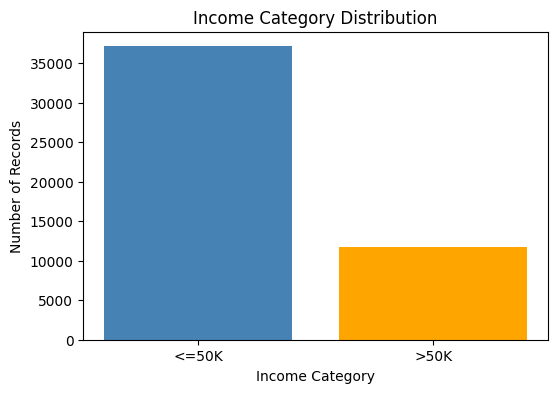

In [ ]:
# Create a bar chart showing the number of records in each income category
income_counts = plot_data["income_group"].value_counts().reindex(["<=50K", ">50K"])

plt.figure(figsize=(6, 4))
plt.bar(income_counts.index, income_counts.values, color=["steelblue", "orange"])
plt.title("Income Category Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of Records")
plt.show()

In [ ]:
# Create a function for 100% stacked bar charts by income category
def income_stacked_bar(variable, title):
    percentages = pd.crosstab(
        plot_data[variable],
        plot_data["income_group"],
        normalize="index").mul(100)

    percentages = percentages.reindex(
        columns=["<=50K", ">50K"],
        fill_value=0)

    percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5),
        color=["steelblue", "orange"])

    plt.title(title)
    plt.xlabel(variable.replace("_", " ").title())
    plt.ylabel("Percentage of Records")
    plt.legend(title="Income Category")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

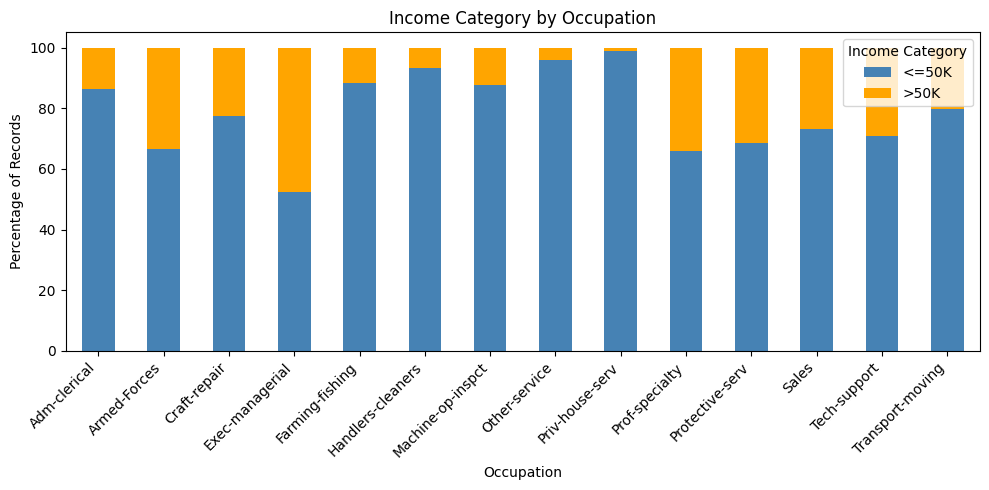

In [ ]:
# Create a 100% stacked bar chart for occupation by income category
income_stacked_bar("occupation", "Income Category by Occupation")

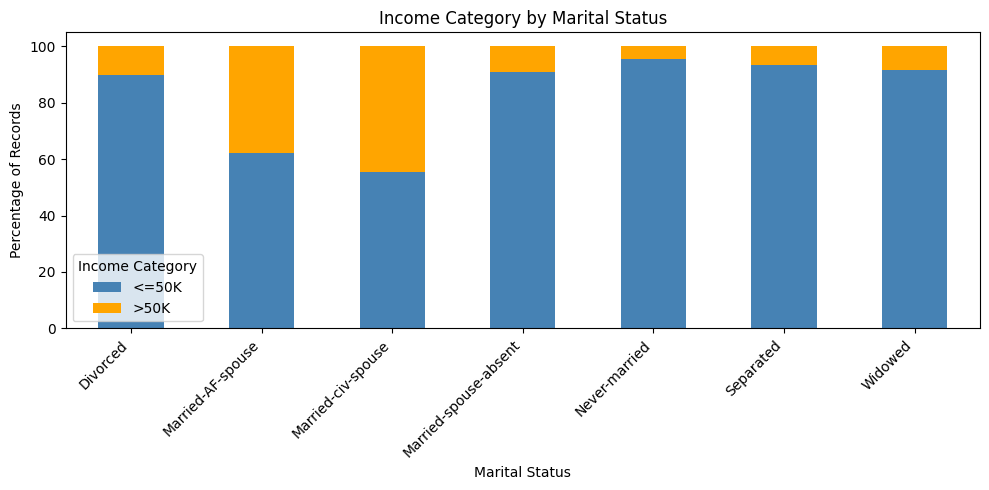

In [ ]:
# Create a 100% stacked bar chart for marital status by income category
income_stacked_bar("marital_status", "Income Category by Marital Status")

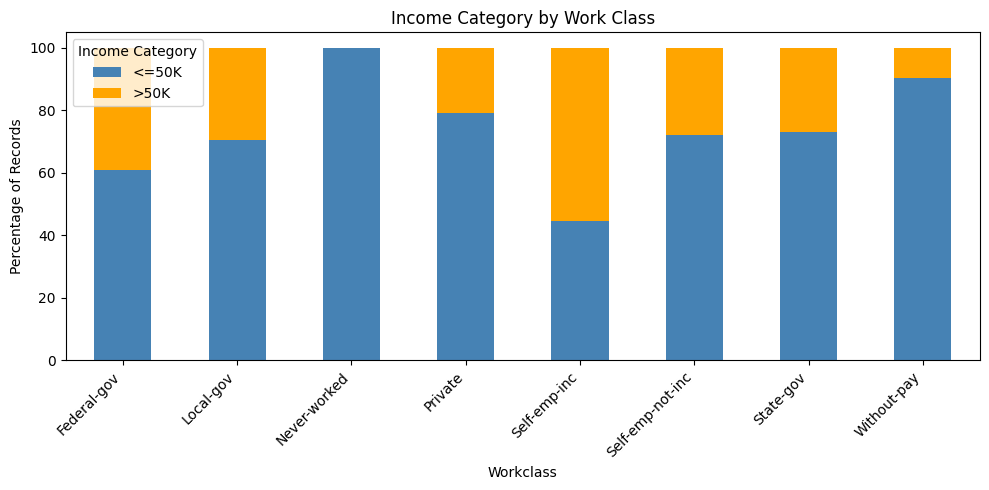

In [ ]:
# Create a 100% stacked bar chart for work class by income category
income_stacked_bar("workclass", "Income Category by Work Class")

In [ ]:
# Import Seaborn for boxplots and scatterplots
import seaborn as sns

In [ ]:
# Create a function for boxplots of numeric variables by income category
def income_boxplot(variable, title):
    plt.figure(figsize=(7, 5))
    sns.boxplot(
        data=plot_data,
        x="income_group",
        y=variable,
        order=["<=50K", ">50K"]
    )
    plt.title(title)
    plt.xlabel("Income Category")
    plt.ylabel(variable.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

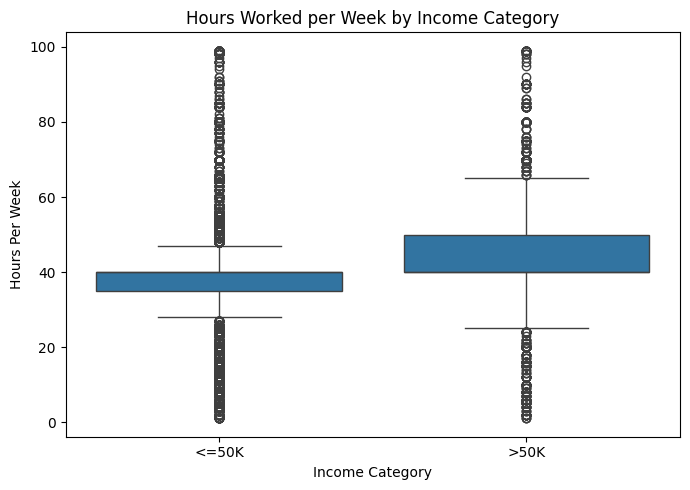

In [ ]:
# Create a boxplot of weekly work hours by income category
income_boxplot(
    "hours_per_week",
    "Hours Worked per Week by Income Category")

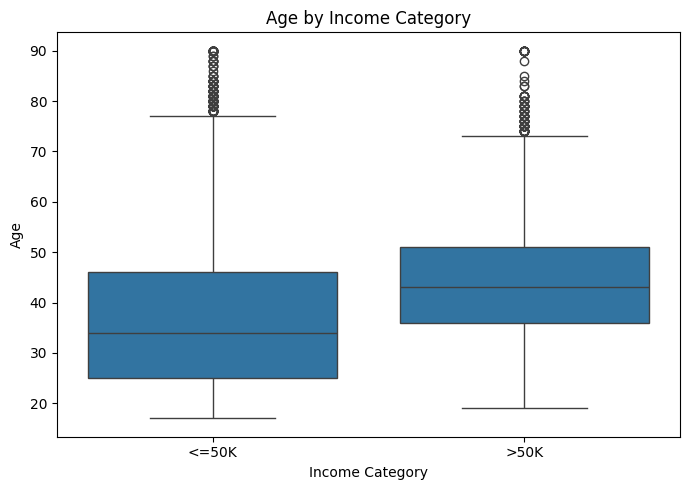

In [ ]:
# Create a boxplot of age by income category
income_boxplot(
    "age",
    "Age by Income Category")

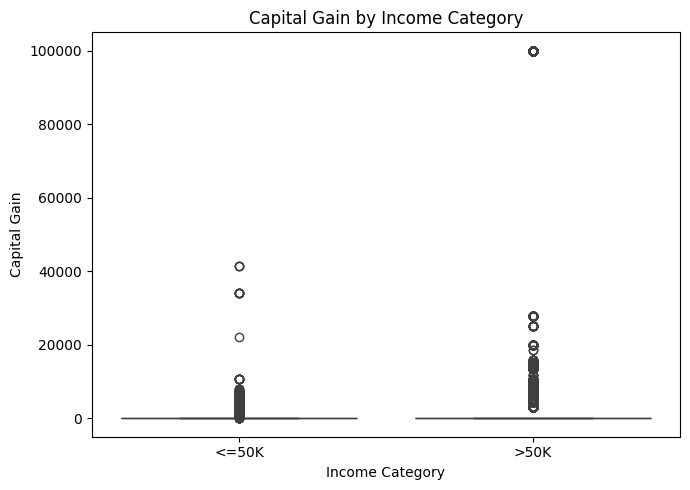

In [ ]:
# Create a boxplot of capital gain by income category
income_boxplot(
    "capital_gain",
    "Capital Gain by Income Category")

In [ ]:
# Import NumPy for numerical transformations
import numpy as np

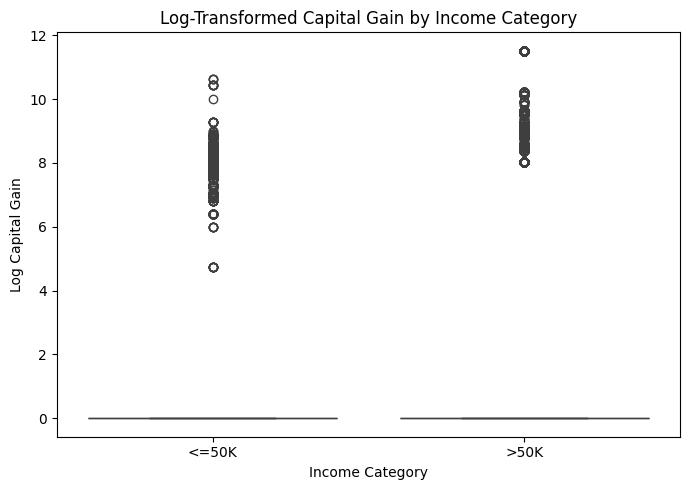

In [ ]:
# Create a log-transformed capital gain variable because capital gain is highly skewed
plot_data["log_capital_gain"] = np.log1p(plot_data["capital_gain"])

# Create a boxplot of log-transformed capital gain by income category
income_boxplot(
    "log_capital_gain",
    "Log-Transformed Capital Gain by Income Category")

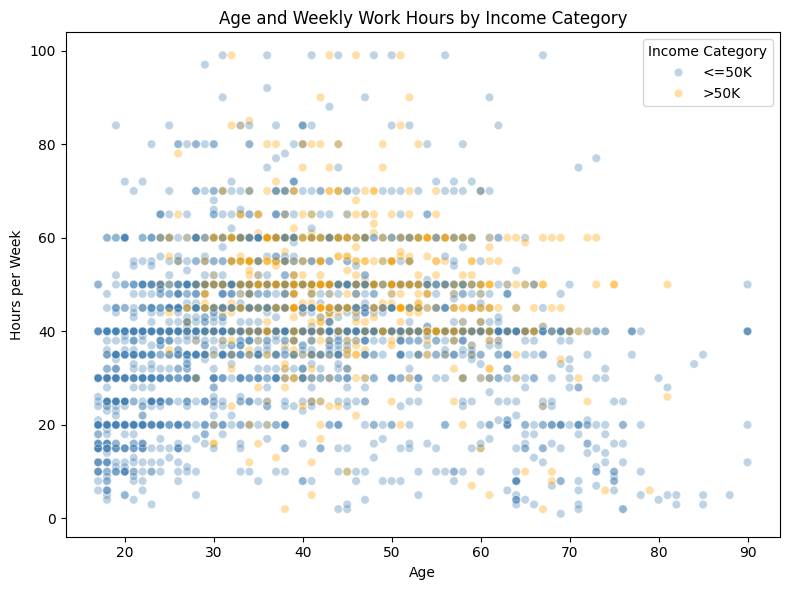

In [ ]:
# Select a reproducible sample of records for a clearer scatterplot
scatter_sample = plot_data.sample(
    n=min(5000, len(plot_data)),
    random_state=42
)

# Create a scatterplot of age and weekly work hours by income category
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=scatter_sample,
    x="age",
    y="hours_per_week",
    hue="income_group",
    alpha=0.35,
    palette={"<=50K": "steelblue", ">50K": "orange"}
)
plt.title("Age and Weekly Work Hours by Income Category")
plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.legend(title="Income Category")
plt.tight_layout()
plt.show()

# Modeling - Random Forest

In [ ]:
# Convert current categorical variables from its current type into a pandas categorical variable.
data_new['workclass'] = data_new['workclass'].astype(pd.CategoricalDtype())
data_new['marital_status'] = data_new['marital_status'].astype(pd.CategoricalDtype())
data_new['occupation'] = data_new['occupation'].astype(pd.CategoricalDtype())
data_new['relationship'] = data_new['relationship'].astype(pd.CategoricalDtype())
data_new['native_country'] = data_new['native_country'].astype(pd.CategoricalDtype())

In [ ]:
# Replace each categorical predictor with a numeric category code for random forest modeling.
data_new['workclass'] = data_new['workclass'].cat.codes
data_new['marital_status'] = data_new['marital_status'].cat.codes
data_new['occupation'] = data_new['occupation'].cat.codes
data_new['relationship'] = data_new['relationship'].cat.codes
data_new['native_country'] = data_new['native_country'].cat.codes

In [ ]:
data_new.head(10)

,age,workclass,education_num,marital_status,occupation,relationship,capital_gain,capital_loss,hours_per_week,native_country,income_binary
0,39,6,13,4,0,1,2174,0,40,38,1
1,50,5,13,2,3,0,0,0,13,38,1
2,38,3,9,0,5,1,0,0,40,38,1
3,53,3,7,2,5,0,0,0,40,38,1
4,28,3,13,2,9,5,0,0,40,4,1
5,37,3,14,2,3,5,0,0,40,38,1
6,49,3,5,3,7,1,0,0,16,22,1
7,52,5,9,2,3,0,0,0,45,38,0
8,31,3,14,4,9,1,14084,0,50,38,0
9,42,3,13,2,3,0,5178,0,40,38,0


In [ ]:
# Display the data type assigned to each column in the updated dataset
data_new.dtypes

,0
age,int64
workclass,int8
education_num,int64
marital_status,int8
occupation,int8
relationship,int8
capital_gain,int64
capital_loss,int64
hours_per_week,int64
native_country,int8


In [ ]:
# Installs the dmba package, which provides helper functions used later for visualizing and evaluating models.
!pip install dmba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 63.8 MB/s eta 0:00:00


In [ ]:
# Imports pandas as pd so we can load and work with tabular data.
import pandas as pd
# Imports the random-forest classifier, which combines many decision trees for classification.
from sklearn.ensemble import RandomForestClassifier
# Imports the function used to split data into training and testing sets.
from sklearn.model_selection import train_test_split
# Imports the dmba package.
import dmba
# Import the function used to evaluate classification results
from dmba import classificationSummary

Colab environment detected.


In [ ]:
# Creates the predictor matrix X by removing the income_binary target column from the dataset.
X = data_new.drop(columns=['income_binary'])
# Creates the target vector y using the income_binary column.
y = data_new['income_binary']

In [ ]:
# Splits X and y into 80% training data and 20% testing data, using a fixed random seed.
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=42)

### Unrestricted Random Forest

In [ ]:
# Creates a random-forest classifier containing 500 decision trees and fixes the random seed.
rf1 = RandomForestClassifier(n_estimators=500, random_state=42)
# Trains the random-forest classifier on the training data.
rf1.fit(train_X, train_y)

RandomForestClassifier(n_estimators=500, random_state=42)

In [ ]:
# Evaluates the random forest on the training data by comparing actual and predicted classes.
classificationSummary(train_y, rf1.predict(train_X))

Confusion Matrix (Accuracy 0.9704)

       Prediction
Actual     0     1
     0  8576   721
     1   434 29319


In [ ]:
# Evaluates the random forest on the test data by comparing actual and predicted classes.
classificationSummary(test_y, rf1.predict(test_X))

Confusion Matrix (Accuracy 0.8473)

       Prediction
Actual    0    1
     0 1496  892
     1  599 6776


### Restricted Random Forest

In [ ]:
# Creates a random-forest classifier containing 500 decision trees and fixes a random forest and random seed.
rf2 = RandomForestClassifier(n_estimators=500, max_depth=5, random_state=42)
# Trains the random-forest classifier on the training data.
rf2.fit(train_X, train_y)

RandomForestClassifier(max_depth=5, n_estimators=500, random_state=42)

In [ ]:
# Evaluates the random forest on the training data by comparing actual and predicted classes.
classificationSummary(train_y, rf2.predict(train_X))

Confusion Matrix (Accuracy 0.8542)

       Prediction
Actual     0     1
     0  4719  4578
     1  1115 28638


In [ ]:
# Evaluates the random forest on the test data by comparing actual and predicted classes.
classificationSummary(test_y, rf2.predict(test_X))

Confusion Matrix (Accuracy 0.8523)

       Prediction
Actual    0    1
     0 1232 1156
     1  286 7089


In [ ]:
# Creates a random-forest classifier containing 500 decision trees and fixes a random forest and random seed.
rf3 = RandomForestClassifier(n_estimators=500, max_depth=10, random_state=42)
# Trains the random-forest classifier on the training data.
rf3.fit(train_X, train_y)

RandomForestClassifier(max_depth=10, n_estimators=500, random_state=42)

In [ ]:
# Evaluates the random forest on the training data by comparing actual and predicted classes.
classificationSummary(train_y, rf3.predict(train_X))

Confusion Matrix (Accuracy 0.8702)

       Prediction
Actual     0     1
     0  5376  3921
     1  1146 28607


In [ ]:
# Evaluates the random forest on the test data by comparing actual and predicted classes.
classificationSummary(test_y, rf3.predict(test_X))

Confusion Matrix (Accuracy 0.8635)

       Prediction
Actual    0    1
     0 1390  998
     1  335 7040


In [ ]:
# Creates a random-forest classifier containing 500 decision trees and fixes a random forest and random seed.
rf4 = RandomForestClassifier(n_estimators=500, max_depth=15, random_state=42)
# Trains the random-forest classifier on the training data.
rf4.fit(train_X, train_y)

RandomForestClassifier(max_depth=15, n_estimators=500, random_state=42)

In [ ]:
# Evaluates the random forest on the training data by comparing actual and predicted classes.
classificationSummary(train_y, rf4.predict(train_X))

Confusion Matrix (Accuracy 0.9008)

       Prediction
Actual     0     1
     0  6540  2757
     1  1117 28636


In [ ]:
# Evaluates the random forest on the test data by comparing actual and predicted classes.
classificationSummary(test_y, rf4.predict(test_X))

Confusion Matrix (Accuracy 0.8649)

       Prediction
Actual    0    1
     0 1485  903
     1  416 6959


In [ ]:
# Creates a random-forest classifier containing 500 decision trees and fixes a random forest and random seed.
rf5 = RandomForestClassifier(n_estimators=500, max_depth=20, random_state=42)
# Trains the random-forest classifier on the training data.
rf5.fit(train_X, train_y)

RandomForestClassifier(max_depth=20, n_estimators=500, random_state=42)

In [ ]:
# Evaluates the random forest on the training data by comparing actual and predicted classes.
classificationSummary(train_y, rf5.predict(train_X))

Confusion Matrix (Accuracy 0.9378)

       Prediction
Actual     0     1
     0  7681  1616
     1   814 28939


In [ ]:
# Evaluates the random forest on the test data by comparing actual and predicted classes.
classificationSummary(test_y, rf5.predict(test_X))

Confusion Matrix (Accuracy 0.8610)

       Prediction
Actual    0    1
     0 1505  883
     1  474 6901
